# NB5e — ความต่างระหว่าง session อธิบายผลที่กลับทิศได้ไหม

**คำถามจากการนำเสนอ** ไฟล์ก่อนและหลังทำงานเป็นคนละ recording กัน ค่าที่ต่างกัน
อาจมาจากเครื่อง ไม่ใช่จากสมอง — เช่น impedance เปลี่ยน อิเล็กโทรดขยับ หรือ gain ไม่เท่าเดิม
ต้องปรับให้อยู่บน baseline เดียวกันก่อนไหม

**ตรรกะ** ความต่างระหว่าง session แบบที่พบบ่อยที่สุดคือ**การคูณทั้งสเปกตรัมด้วยค่าคงที่**
(gain หรือ impedance) ในสเกล log มันคือการบวกค่าคงที่เท่ากันทุกความถี่ ซึ่งแปลว่า

| ตัววัด | นิยาม | โดนผลจากการคูณไหม |
|---|---|---|
| `low_alpha_corr` | log กำลัง − เส้น 1/f ที่ fit ได้ | **ไม่** ค่าคงที่ไปโผล่ที่ offset ของเส้น fit แล้วลบทิ้งไปพร้อมกัน |
| `low_alpha_rel` | กำลังในแถบ ÷ กำลังรวม | **ไม่** ค่าคงที่ตัดกันในเศษกับส่วน |
| `low_alpha_corr_rel` | ทั้งสองอย่างรวมกัน | **ไม่** |
| `ap_exponent` | ความชันของเส้น 1/f | **ไม่** การบวกค่าคงที่ไม่เปลี่ยนความชัน |
| `ap_offset` | ความสูงของเส้น 1/f | **ใช่** นี่คือตัวเดียวที่ดูดค่าคงที่นั้นไว้ |

ถ้าตรรกะนี้ถูก ผลที่กลับทิศของ low alpha จะอธิบายด้วยความต่างระหว่าง session ไม่ได้
และแถวที่น่าสงสัยคือ offset ซึ่งเป็นแถวที่เราไม่ตีความอยู่แล้ว

**สามด่านที่ตรวจในไฟล์นี้**
1. มีการเลื่อนระดับระหว่าง session จริงไหม และใหญ่แค่ไหน
2. การเปลี่ยนของ low alpha เดินตามการเลื่อนระดับหรือเปล่า
3. ถ้าดูเฉพาะคนที่ระดับแทบไม่เลื่อน low alpha ยังเพิ่มอยู่ไหม

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr
import warnings; warnings.filterwarnings('ignore')

REG  = ['frontal', 'central', 'occipital']
MEAS = ['low_alpha_corr', 'high_alpha_corr', 'low_alpha_rel', 'high_alpha_rel',
        'low_alpha_corr_rel', 'high_alpha_corr_rel', 'ap_exponent', 'ap_offset']

f4 = pd.read_csv('outputs/fooof_features_v4.csv')
print("คอลัมน์ที่มี:", sorted(f4.columns), "\n")
f4 = f4[(f4.task == 'EyesClosed') & (f4.ap_exponent > 0)].copy()

# Δ = หลัง − ก่อน ของคนเดียวกัน แยกตามบริเวณ
parts = []
for m in MEAS:
    p = f4.pivot_table(index=['subject', 'region'], columns='condition', values=m).dropna()
    parts.append((p['post'] - p['pre']).rename(m))
DD = pd.concat(parts, axis=1).dropna().reset_index()
DD = DD[DD.region.isin(REG)]
print(DD.groupby('region').size().to_string(), "\n")
print("ตัวอย่างตารางผลต่าง (หน่วยเป็น log)")
print(DD.head(3).round(4).to_string(index=False))

คอลัมน์ที่มี: ['ap_exponent', 'ap_exponent_f40', 'ap_offset', 'ap_offset_f40', 'condition', 'file', 'good_frac', 'high_alpha_corr', 'high_alpha_corr_f40', 'high_alpha_corr_rel', 'high_alpha_rel', 'low_alpha_corr', 'low_alpha_corr_f40', 'low_alpha_corr_rel', 'low_alpha_rel', 'n_chan', 'n_eog_excluded', 'n_muscle_excluded', 'region', 'subject', 'task'] 

region
central      607
frontal      608
occipital    607 

ตัวอย่างตารางผลต่าง (หน่วยเป็น log)
subject    region  low_alpha_corr  high_alpha_corr  low_alpha_rel  high_alpha_rel  low_alpha_corr_rel  high_alpha_corr_rel  ap_exponent  ap_offset
sub-001   central          0.1760           0.0800         0.0357          0.1080              0.0509               0.1294      -0.3487    -0.5166
sub-001   frontal          0.1586           0.0019         0.0273          0.0648              0.0413               0.0695      -0.1713    -0.2019
sub-001 occipital          0.1080          -0.0783         0.0009          0.0304             -0.0028       

In [2]:
print("ด่าน 1 · การเลื่อนระดับระหว่าง session ใหญ่แค่ไหน\n")
print(f"{'บริเวณ':<12}{'Δoffset กลาง':>14}{'= คูณกี่เท่า':>14}{'IQR':>22}{'p':>10}")
for r in REG:
    d = DD[DD.region == r]
    med = d.ap_offset.median()
    q1, q3 = d.ap_offset.quantile([.25, .75])
    _, p = wilcoxon(d.ap_offset)
    print(f"{r:<12}{med:>+14.4f}{10**med:>14.3f}{f'{q1:+.3f} ถึง {q3:+.3f}':>22}{p:>10.2g}")

print("\nด่าน 2 · การเปลี่ยนของ low alpha เดินตามการเลื่อนระดับหรือเปล่า\n")
print("ถ้าเป็นการคูณค่าคงที่ล้วน ๆ ค่าที่หัก 1/f แล้วจะไม่ขยับตาม สิ่งที่คาดไว้คือ rho ใกล้ศูนย์\n")
print(f"{'บริเวณ':<12}{'ตัววัด':<8}{'Spearman rho':>14}{'p':>12}")
for r in REG:
    d = DD[DD.region == r]
    for i, (lab, col) in enumerate([('corr', 'low_alpha_corr'), ('rel', 'low_alpha_rel')]):
        rho, p = spearmanr(d.ap_offset, d[col])
        print(f"{r if i == 0 else '':<12}{lab:<8}{rho:>+14.3f}{p:>12.2g}")

print("""
อ่านยังไง  ทั้งสองตัววัดติดลบใกล้เคียงกัน ซึ่งไม่ได้แปลว่าระดับสัญญาณขับการเปลี่ยนของ alpha
          แต่แปลว่าทั้งคู่มี offset อยู่ในสูตรของมันเอง — _corr ลบเส้นที่ offset เป็นความสูง
          ส่วน _rel หารด้วยกำลังรวมซึ่ง offset เป็นตัวกำหนดหลัก จึงติดลบโดยอัตโนมัติทั้งคู่
          ตอนแรกเราคิดว่า _rel เป็นตัวตรวจอิสระ พอคำนวณจริงพบว่าไม่ใช่
          ด่าน 2 จึงใช้เป็นหลักฐานไม่ได้ ไม่ว่าทิศไหน · หลักฐานที่ใช้ได้คือด่าน 3 กับ 3b""")

ด่าน 1 · การเลื่อนระดับระหว่าง session ใหญ่แค่ไหน

บริเวณ        Δoffset กลาง  = คูณกี่เท่า                   IQR         p
frontal            -0.0401         0.912     -0.193 ถึง +0.123   0.00044
central            -0.0379         0.916     -0.164 ถึง +0.065   4.5e-09
occipital          -0.0065         0.985     -0.117 ถึง +0.133      0.89

ด่าน 2 · การเปลี่ยนของ low alpha เดินตามการเลื่อนระดับหรือเปล่า

ถ้าเป็นการคูณค่าคงที่ล้วน ๆ ค่าที่หัก 1/f แล้วจะไม่ขยับตาม สิ่งที่คาดไว้คือ rho ใกล้ศูนย์

บริเวณ      ตัววัด    Spearman rho           p
frontal     corr            -0.292       2e-13
            rel             -0.381     2.1e-22
central     corr            -0.235     4.7e-09
            rel             -0.246     7.9e-10
occipital   corr            -0.238     2.7e-09
            rel             -0.205     3.4e-07

อ่านยังไง  ทั้งสองตัววัดติดลบใกล้เคียงกัน ซึ่งไม่ได้แปลว่าระดับสัญญาณขับการเปลี่ยนของ alpha
          แต่แปลว่าทั้งคู่มี offset อยู่ในสูตรของมันเอง — _corr ลบเส้นที่ offs

In [3]:
print("ด่าน 3 · แบ่งครึ่งตามขนาดการเลื่อนระดับ แล้วทดสอบ low alpha แยกกัน\n")
rows = []
for r in REG:
    d   = DD[DD.region == r].copy()
    thr = d.ap_offset.abs().median()
    for name, g in [('ระดับแทบไม่เลื่อน', d[d.ap_offset.abs() <= thr]),
                    ('ระดับเลื่อนเยอะ',   d[d.ap_offset.abs() >  thr])]:
        for meas in ['low_alpha_corr', 'low_alpha_rel', 'low_alpha_corr_rel']:
            v = g[meas]
            _, p = wilcoxon(v)
            rows.append({'region': r, 'group': name, 'meas': meas, 'n': len(v),
                         'thr': thr, 'med': v.median(), 'up': (v > 0).mean(), 'p': p})
res = pd.DataFrame(rows)
res['p_bonf'] = np.minimum(res.p * len(res), 1.0)

for r in REG:
    sub = res[res.region == r]
    print(f"── {r}  (เส้นแบ่ง |Δoffset| = {sub.thr.iloc[0]:.4f} คือคูณ {10**sub.thr.iloc[0]:.3f} เท่า)")
    for _, x in sub.iterrows():
        mark = '✓' if x['p_bonf'] < 0.05 else ' '
        print(f"   {x['group']:<18}{x['meas']:<20}n={x['n']:>3}  "
              f"กลาง {x['med']:+.4f}  เพิ่มขึ้น {x['up']:.0%}  p={x['p_bonf']:.2g} {mark}")
    print()

n_sig = (res.p_bonf < 0.05).sum()
n_up  = (res.med > 0).sum()
print(f"สรุป  {n_sig}/{len(res)} ช่องมีนัยสำคัญหลังแก้ค่า Bonferroni · "
      f"{n_up}/{len(res)} ช่องมีค่ากลางเป็นบวก คือเพิ่มขึ้น")
res.to_csv('outputs/nb5e_offset_split.csv', index=False)

ด่าน 3 · แบ่งครึ่งตามขนาดการเลื่อนระดับ แล้วทดสอบ low alpha แยกกัน

── frontal  (เส้นแบ่ง |Δoffset| = 0.1643 คือคูณ 1.460 เท่า)
   ระดับแทบไม่เลื่อน low_alpha_corr      n=304  กลาง +0.0838  เพิ่มขึ้น 73%  p=4.3e-19 ✓
   ระดับแทบไม่เลื่อน low_alpha_rel       n=304  กลาง +0.0182  เพิ่มขึ้น 70%  p=4.6e-13 ✓
   ระดับแทบไม่เลื่อน low_alpha_corr_rel  n=304  กลาง +0.0336  เพิ่มขึ้น 66%  p=2.8e-10 ✓
   ระดับเลื่อนเยอะ   low_alpha_corr      n=304  กลาง +0.1082  เพิ่มขึ้น 73%  p=7.1e-20 ✓
   ระดับเลื่อนเยอะ   low_alpha_rel       n=304  กลาง +0.0269  เพิ่มขึ้น 73%  p=1.8e-15 ✓
   ระดับเลื่อนเยอะ   low_alpha_corr_rel  n=304  กลาง +0.0387  เพิ่มขึ้น 70%  p=3.7e-14 ✓

── central  (เส้นแบ่ง |Δoffset| = 0.1168 คือคูณ 1.309 เท่า)
   ระดับแทบไม่เลื่อน low_alpha_corr      n=304  กลาง +0.0777  เพิ่มขึ้น 74%  p=3.7e-18 ✓
   ระดับแทบไม่เลื่อน low_alpha_rel       n=304  กลาง +0.0208  เพิ่มขึ้น 71%  p=3.9e-15 ✓
   ระดับแทบไม่เลื่อน low_alpha_corr_rel  n=304  กลาง +0.0348  เพิ่มขึ้น 71%  p=4.8e-13 ✓
   ระดับเล

In [4]:
print("ด่าน 3b · เกณฑ์สัมบูรณ์ เฉพาะคนที่ระดับแทบไม่เปลี่ยนจริง ๆ\n")
for thr in [0.05, 0.02]:
    print(f"── |Δoffset| < {thr}  คือระดับเปลี่ยนไม่เกิน {(10**thr - 1) * 100:.0f}%")
    for r in REG:
        d = DD[(DD.region == r) & (DD.ap_offset.abs() < thr)]
        for lab, col in [('corr', 'low_alpha_corr'), ('rel', 'low_alpha_rel')]:
            v = d[col]
            if len(v) < 20:
                print(f"   {r:<11}{lab:<6}n={len(v):>3}  น้อยเกินไป"); continue
            _, p = wilcoxon(v)
            print(f"   {r:<11}{lab:<6}n={len(v):>3}  กลาง {v.median():+.4f}  "
                  f"เพิ่มขึ้น {(v > 0).mean():.0%}  p={p:.2g}  p_bonf={min(p*12, 1):.2g}")
    print()

ด่าน 3b · เกณฑ์สัมบูรณ์ เฉพาะคนที่ระดับแทบไม่เปลี่ยนจริง ๆ

── |Δoffset| < 0.05  คือระดับเปลี่ยนไม่เกิน 12%
   frontal    corr  n=107  กลาง +0.0770  เพิ่มขึ้น 66%  p=6.7e-07  p_bonf=8e-06
   frontal    rel   n=107  กลาง +0.0158  เพิ่มขึ้น 66%  p=7.8e-06  p_bonf=9.4e-05
   central    corr  n=153  กลาง +0.0757  เพิ่มขึ้น 76%  p=4.6e-11  p_bonf=5.6e-10
   central    rel   n=153  กลาง +0.0232  เพิ่มขึ้น 75%  p=1.5e-09  p_bonf=1.8e-08
   occipital  corr  n=120  กลาง +0.0899  เพิ่มขึ้น 72%  p=4.2e-07  p_bonf=5e-06
   occipital  rel   n=120  กลาง +0.0273  เพิ่มขึ้น 70%  p=1e-05  p_bonf=0.00012

── |Δoffset| < 0.02  คือระดับเปลี่ยนไม่เกิน 5%
   frontal    corr  n= 41  กลาง +0.0378  เพิ่มขึ้น 61%  p=0.019  p_bonf=0.23
   frontal    rel   n= 41  กลาง +0.0173  เพิ่มขึ้น 63%  p=0.0026  p_bonf=0.031
   central    corr  n= 62  กลาง +0.0843  เพิ่มขึ้น 82%  p=1.4e-07  p_bonf=1.7e-06
   central    rel   n= 62  กลาง +0.0295  เพิ่มขึ้น 84%  p=8.7e-07  p_bonf=1e-05
   occipital  corr  n= 51  กลาง +0.0896 

In [5]:
from scipy.stats import linregress, t as tdist

print("ด่าน 3c · ถอด Δoffset ออกด้วยการถดถอย แล้วดูค่าที่ Δoffset = 0\n")
for r in REG:
    d = DD[DD.region == r]
    for lab, col in [('corr', 'low_alpha_corr'), ('rel', 'low_alpha_rel'),
                     ('corr_rel', 'low_alpha_corr_rel')]:
        g = linregress(d.ap_offset, d[col])
        tv = g.intercept / g.intercept_stderr
        p  = 2 * tdist.sf(abs(tv), len(d) - 2)
        print(f"   {r:<11}{lab:<10}n={len(d):>3}  "
              f"ค่าเมื่อ baseline ไม่เลื่อน {g.intercept:+.4f}  "
              f"p={p:.2g}  p_bonf={min(p*9, 1):.2g}  ความชัน {g.slope:+.3f}")
    print()

ด่าน 3c · ถอด Δoffset ออกด้วยการถดถอย แล้วดูค่าที่ Δoffset = 0

   frontal    corr      n=608  ค่าเมื่อ baseline ไม่เลื่อน +0.0957  p=2.5e-36  p_bonf=2.2e-35  ความชัน -0.163
   frontal    rel       n=608  ค่าเมื่อ baseline ไม่เลื่อน +0.0279  p=6.9e-21  p_bonf=6.2e-20  ความชัน -0.078
   frontal    corr_rel  n=608  ค่าเมื่อ baseline ไม่เลื่อน +0.0447  p=1.2e-19  p_bonf=1.1e-18  ความชัน -0.103

   central    corr      n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0959  p=6.1e-40  p_bonf=5.5e-39  ความชัน -0.160
   central    rel       n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0295  p=9.2e-26  p_bonf=8.3e-25  ความชัน -0.061
   central    corr_rel  n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0447  p=9.8e-23  p_bonf=8.8e-22  ความชัน -0.063

   occipital  corr      n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0975  p=3.6e-30  p_bonf=3.2e-29  ความชัน -0.225
   occipital  rel       n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0329  p=3.5e-19  p_bonf=3.2e-18  ความชัน -0.070
   occipital  corr_rel  n=607  ค่าเมื่อ baseline ไม่เล

In [12]:
from scipy.stats import linregress, t as tdist

print("ด่าน 3c · ถอด Δoffset ออกด้วยการถดถอย แล้วดูค่าที่ Δoffset = 0\n")
rows3c = []
for r in REG:
    d = DD[DD.region == r]
    for lab, col in [('corr', 'low_alpha_corr'), ('rel', 'low_alpha_rel'),
                     ('corr_rel', 'low_alpha_corr_rel')]:
        g  = linregress(d.ap_offset, d[col])
        tv = g.intercept / g.intercept_stderr
        p  = 2 * tdist.sf(abs(tv), len(d) - 2)
        rows3c.append({'region': r, 'meas': col, 'n': len(d),
                       'intercept': g.intercept, 'slope': g.slope,
                       'p': p, 'p_bonf': min(p * 9, 1.0)})
        print(f"   {r:<11}{lab:<10}n={len(d):>3}  "
              f"ค่าเมื่อ baseline ไม่เลื่อน {g.intercept:+.4f}  "
              f"p={p:.2g}  p_bonf={min(p*9, 1):.2g}  ความชัน {g.slope:+.3f}")
    print()

res3c = pd.DataFrame(rows3c)
res3c.to_csv('outputs/nb5e_offset_regression.csv', index=False)
print(f"สรุป  {(res3c.p_bonf < 0.05).sum()}/{len(res3c)} ช่องมีนัยสำคัญหลังแก้ค่า Bonferroni · "
      f"{(res3c.intercept > 0).sum()}/{len(res3c)} ช่องจุดตัดแกนเป็นบวก")

ด่าน 3c · ถอด Δoffset ออกด้วยการถดถอย แล้วดูค่าที่ Δoffset = 0

   frontal    corr      n=608  ค่าเมื่อ baseline ไม่เลื่อน +0.0957  p=2.5e-36  p_bonf=2.2e-35  ความชัน -0.163
   frontal    rel       n=608  ค่าเมื่อ baseline ไม่เลื่อน +0.0279  p=6.9e-21  p_bonf=6.2e-20  ความชัน -0.078
   frontal    corr_rel  n=608  ค่าเมื่อ baseline ไม่เลื่อน +0.0447  p=1.2e-19  p_bonf=1.1e-18  ความชัน -0.103

   central    corr      n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0959  p=6.1e-40  p_bonf=5.5e-39  ความชัน -0.160
   central    rel       n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0295  p=9.2e-26  p_bonf=8.3e-25  ความชัน -0.061
   central    corr_rel  n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0447  p=9.8e-23  p_bonf=8.8e-22  ความชัน -0.063

   occipital  corr      n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0975  p=3.6e-30  p_bonf=3.2e-29  ความชัน -0.225
   occipital  rel       n=607  ค่าเมื่อ baseline ไม่เลื่อน +0.0329  p=3.5e-19  p_bonf=3.2e-18  ความชัน -0.070
   occipital  corr_rel  n=607  ค่าเมื่อ baseline ไม่เล

## สรุป

**ระดับโดยรวมลดลงจริง** ที่หน้าผากและกลางศีรษะ หลังทำงานต่ำกว่าก่อนทำงานราว 0.91 เท่า
(p = 0.0004 และ 4.5e-09) ส่วนท้ายทอยไม่เลื่อน (p = 0.89) · ข้อมูลชุดนี้แยกไม่ออกว่า
การลดลงนี้มาจากเครื่องหรือจากสมองที่กำลังรวมลดลงจริง แต่ทั้งสองกรณีไม่ได้สร้างผลของ low alpha

**หลักฐานคือด่าน 3b** เลือกเฉพาะคนที่ระดับโดยรวมเปลี่ยนไม่เกิน 12% เหลือ 107–153 คน
ต่อบริเวณ low alpha ยังเพิ่มขึ้นทั้ง 6 ช่อง ค่ากลาง +0.076 ถึง +0.090 ซึ่งแทบเท่ากับ
ตอนใช้ทั้งกลุ่ม (+0.088 ถึง +0.091) ถ้าการเลื่อนระดับเป็นต้นเหตุ กลุ่มนี้ต้องไม่เห็นผล

**หลักฐานคือด่าน 3c** ถดถอย Δ low alpha บน Δ offset แล้วอ่านค่าที่จุดตัดแกน
ซึ่งคือค่าที่คาดว่าจะเห็นเมื่อระดับไม่เลื่อนเลย ได้ +0.096 ถึง +0.098 สำหรับตัววัดที่ลบ 1/f
มีนัยสำคัญครบทั้ง 9 ช่องหลังแก้ค่า Bonferroni โดยใช้ผู้เข้าร่วมครบ 607–608 คน ไม่ต้องตัดใครออก
และไม่เล็กลงจากค่ากลางทั้งกลุ่มที่ +0.088 ถึง +0.091

**ด่าน 3 กับ 3b ใช้เป็นเช็กสำรอง** ตัดคนที่ระดับเปลี่ยนเกิน 12% ออกก็ยังเพิ่มทั้ง 6 ช่อง
แต่พอบีบเป็น 5% เหลือ 41–62 คน หน้าผากบน `_corr` หดเหลือ +0.038 และไม่ผ่านการแก้ค่า
การถดถอยจึงดีกว่าเพราะไม่ต้องเสียตัวอย่าง

**ความชันติดลบทั้ง 9 ช่องไม่ตีความ** เป็นผลจากนิยามเดียวกับที่ทำให้ rho ในด่าน 2 ใช้ไม่ได้

**เหตุผลเชิงนิยาม** ตัววัด alpha ทั้งสามแบบหักระดับโดยรวมออกไปแล้วตั้งแต่ตอนนิยาม
`_corr` ลบเส้น 1/f ที่ fit จากสเปกตรัมเดียวกันนั้น ส่วน `_rel` หารด้วยกำลังรวม
การคูณทั้งสเปกตรัมด้วยค่าคงที่จึงตัดกันทั้งคู่ — **เราทำ baseline normalization
ไปแล้วตั้งแต่เลือกนิยามตัววัด โดยไม่ได้เรียกมันแบบนั้น**

### สิ่งที่ยังพูดไม่ได้

- **ค่า rho ของด่าน 2 ใช้เป็นหลักฐานไม่ได้เลย** ตัววัด alpha ทุกตัวมี offset อยู่ใน
  สูตรของมันเอง `_corr` ลบเส้นที่ offset เป็นความสูง ส่วน `_rel` หารด้วยกำลังรวม
  ซึ่ง offset กำหนดเป็นหลัก ทั้งสองจึงติดลบโดยอัตโนมัติ (`_corr` −0.23 ถึง −0.29 ·
  `_rel` −0.21 ถึง −0.38) ค่านี้ไม่บอกอะไรเกี่ยวกับสาเหตุ ไม่ว่าทิศไหน ·
  ตอนแรกเราคิดว่า `_rel` เป็นตัวตรวจอิสระ พอคำนวณจริงพบว่าไม่ใช่
- **บีบเกณฑ์เป็นไม่เกิน 5% แล้วหน้าผากอ่อนลง** เหลือ 41–62 คนต่อบริเวณ ยังเพิ่มทั้ง
  6 ช่อง และ 11 จาก 12 การทดสอบผ่าน Bonferroni · ที่ไม่ผ่านคือหน้าผากบน `_corr`
  ซึ่งค่ากลางหดจาก +0.091 เหลือ +0.038 (p = 0.23 หลังแก้ค่า) ที่หน้าผากขนาดของผล
  จึงขึ้นกับการเลื่อนระดับอยู่บ้าง แต่ `_rel` ที่บริเวณเดียวกันยังผ่าน และกลางศีรษะ
  กับท้ายทอยไม่หดเลย
- **วิธีนี้แก้ได้เฉพาะความต่างแบบคูณค่าคงที่** ถ้าอิเล็กโทรดขยับจนรับสัญญาณจาก
  แหล่งกำเนิดคนละชุด การ normalize แบบไหนก็แก้ไม่ได้ ต้องแก้ที่การออกแบบการทดลอง

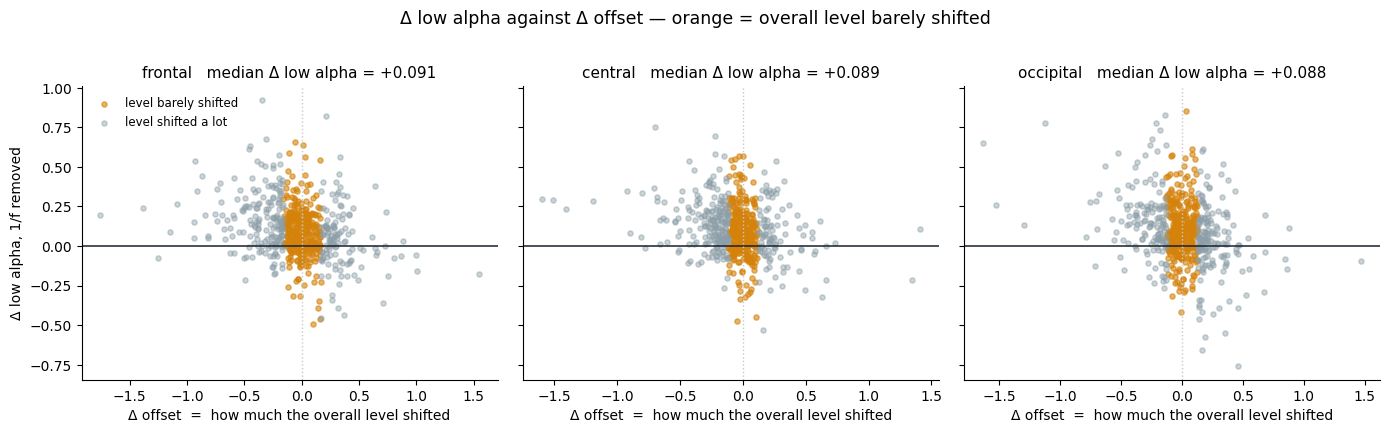

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, r in zip(axes, REG):
    d = DD[DD.region == r]
    thr = d.ap_offset.abs().median()
    small = d.ap_offset.abs() <= thr
    ax.scatter(d.ap_offset[small], d.low_alpha_corr[small], s=14, alpha=.6,
               color='#d4820a', label='level barely shifted')
    ax.scatter(d.ap_offset[~small], d.low_alpha_corr[~small], s=14, alpha=.45,
               color='#8c9ea8', label='level shifted a lot')
    ax.axhline(0, color='#16222e', lw=1.1)
    ax.axvline(0, color='#c8c8c8', lw=1, ls=':')
    ax.set_title(f'{r}   median Δ low alpha = {d.low_alpha_corr.median():+.3f}', fontsize=11)
    ax.set_xlabel('Δ offset  =  how much the overall level shifted')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Δ low alpha, 1/f removed')
axes[0].legend(fontsize=8.5, frameon=False, loc='upper left')
fig.suptitle('Δ low alpha against Δ offset — orange = overall level barely shifted',
             fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig('outputs/nb5e_offset_vs_alpha.png', dpi=150, bbox_inches='tight'); plt.show()

---

## ส่วนที่สอง — ตามหาจุดที่ต่างจากเปเปอร์

เปเปอร์ต้นทางคือ Yang et al. (2025) *Brain Sciences* 15(6):546 ซึ่งใช้ชุดข้อมูลเดียวกัน
พออ่านตัวเปเปอร์จริงพบว่า **เขาไม่ได้ระบุว่าวิเคราะห์เงื่อนไขหลับตาหรือลืมตา**
และเขาเหลือผู้เข้าร่วม 425 คน จากการนิยามสองกลุ่มอายุคือ 20–34 กับ 51–70
แล้วตัดช่วงกลางทิ้ง ส่วนนิยามแถบความถี่เป็น 8–10 กับ 10–13 Hz ตายตัว เหมือนเราเป๊ะ

สองเซลล์ถัดไปไล่ทดสอบทุกทางเลือกที่อาจทำให้ผลต่างกัน ถ้าช่องไหนกลับทิศเป็นลบ
นั่นคือจุดที่ต่าง

**ข้อสังเกตเชิงตรรกะ** การเปลี่ยนวิธีทดสอบสถิติทำให้เครื่องหมายกลับทิศไม่ได้
ค่ากลางของเราเป็นบวกทุกช่อง ต่อให้ใช้ linear mixed model แบบเขาก็ยังเป็นบวก
สาเหตุจึงต้องอยู่ที่การเลือกข้อมูลหรือการประมวลผล ไม่ใช่ที่สถิติ

In [7]:
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
import warnings; warnings.filterwarnings('ignore')

f4 = pd.read_csv('outputs/fooof_features_v4.csv')
print("task ที่มี:", f4.task.unique())

# อายุไม่ได้อยู่ในไฟล์นี้ ต้องดึงจาก participants.tsv
part = pd.read_csv('Dataset/participants.tsv', sep='\t')
print("คอลัมน์ participants:", list(part.columns))
AGE = 'age' if 'age' in part.columns else [c for c in part.columns if 'age' in c.lower()][0]
part = part.rename(columns={'participant_id': 'subject', AGE: 'age'})[['subject', 'age']]
f4 = f4.merge(part, on='subject', how='left')
print(f"จับคู่อายุได้ {f4.age.notna().mean():.0%} ของแถว · ช่วงอายุ {f4.age.min():.0f}–{f4.age.max():.0f}\n")

def direction(d, meas='low_alpha_corr'):
    """คืนค่ากลางของผลต่าง หลัง − ก่อน ต่อบริเวณ"""
    out = []
    for r in ['frontal', 'central', 'occipital']:
        p = (d[d.region == r]
             .pivot_table(index='subject', columns='condition', values=meas).dropna())
        if len(p) < 20:
            out.append((r, len(p), np.nan, np.nan)); continue
        v = p['post'] - p['pre']
        _, pv = wilcoxon(v)
        out.append((r, len(p), v.median(), pv))
    return out

print(f"{'เงื่อนไข':<42}{'บริเวณ':<11}{'n':>5}{'Δ กลาง':>10}{'p':>10}  ทิศ")
print("─" * 92)
for task in ['EyesClosed', 'EyesOpen']:
    for agename, agemask in [
            ('ทุกอายุ',          lambda s: s.age.notna()),
            ('เฉพาะ 20-34 + 51-70', lambda s: s.age.between(20, 34) | s.age.between(51, 70))]:
        for qname, qmask in [
                ('คุณภาพทุกระดับ', lambda s: s.good_frac.notna()),
                ('good_frac > 0.8', lambda s: s.good_frac > 0.8)]:
            d = f4[(f4.task == task) & (f4.ap_exponent > 0)]
            d = d[agemask(d) & qmask(d)]
            lbl = f"{task} · {agename} · {qname}"
            for r, n, med, pv in direction(d):
                if np.isnan(med):
                    print(f"{lbl:<42}{r:<11}{n:>5}   ข้อมูลไม่พอ"); lbl = ""
                    continue
                arrow = "เพิ่ม ↑" if med > 0 else "ลด ↓ ← ตรงกับเปเปอร์"
                print(f"{lbl:<42}{r:<11}{n:>5}{med:>+10.4f}{pv:>10.2g}  {arrow}")
                lbl = ""
            print()

task ที่มี: ['EyesClosed' 'EyesOpen']
คอลัมน์ participants: ['participant_id', 'sex', 'age', 'handedness', 'session1', 'late_ses1', 'session2', 'late_ses2']
จับคู่อายุได้ 100% ของแถว · ช่วงอายุ 20–70

เงื่อนไข                                  บริเวณ         n    Δ กลาง         p  ทิศ
────────────────────────────────────────────────────────────────────────────────────────────
EyesClosed · ทุกอายุ · คุณภาพทุกระดับ     frontal      608   +0.0912   1.3e-39  เพิ่ม ↑
                                          central      607   +0.0892     7e-45  เพิ่ม ↑
                                          occipital    607   +0.0880   2.4e-31  เพิ่ม ↑

EyesClosed · ทุกอายุ · good_frac > 0.8    frontal      605   +0.0906   8.2e-40  เพิ่ม ↑
                                          central      606   +0.0890   1.1e-44  เพิ่ม ↑
                                          occipital    606   +0.0878   3.9e-31  เพิ่ม ↑

EyesClosed · เฉพาะ 20-34 + 51-70 · คุณภาพทุกระดับfrontal      433   +0.0858   9.3e-27  เพิ่ม

In [8]:
print("① good_frac กระจายยังไง — ตัวกรองเดิมแทบไม่ตัดใคร\n")
g = f4.groupby('subject').good_frac.min()
print(g.describe(percentiles=[.01, .05, .10, .25, .50]).round(3).to_string())

print("\n② ลองเกณฑ์คุณภาพที่เข้มจริง กับช่วง fit อีกแบบ\n")
print(f"{'เงื่อนไข':<46}{'ตัววัด':<20}{'n':>5}{'Δ กลาง':>10}{'p':>10}  ทิศ")
print("─" * 96)
for qname, thr in [('ทุกคน', 0.0), ('ตัดล่าง 25%', g.quantile(.25)),
                   ('ตัดล่าง 50%', g.quantile(.50))]:
    keep = set(g.index[g >= thr])
    for meas in ['low_alpha_corr', 'low_alpha_corr_f40', 'ap_exponent', 'ap_exponent_f40']:
        d = f4[(f4.task == 'EyesClosed') & (f4.ap_exponent > 0)
               & f4.subject.isin(keep) & (f4.region == 'central')]
        p = d.pivot_table(index='subject', columns='condition', values=meas).dropna()
        v = p['post'] - p['pre']
        _, pv = wilcoxon(v)
        want_up = 'low_alpha' in meas          # เปเปอร์บอกว่า alpha ลด exponent เพิ่ม
        match = (v.median() < 0) if want_up else (v.median() > 0)
        print(f"{qname + f'  (good_frac >= {thr:.2f})':<46}{meas:<20}{len(v):>5}"
              f"{v.median():>+10.4f}{pv:>10.2g}  {'← ตรงกับเปเปอร์' if match else 'ยังสวนทาง'}")
    print()

① good_frac กระจายยังไง — ตัวกรองเดิมแทบไม่ตัดใคร

count    608.000
mean       0.986
std        0.040
min        0.488
1%         0.798
5%         0.942
10%        0.970
25%        0.989
50%        0.998
max        1.000

② ลองเกณฑ์คุณภาพที่เข้มจริง กับช่วง fit อีกแบบ

เงื่อนไข                                      ตัววัด                  n    Δ กลาง         p  ทิศ
────────────────────────────────────────────────────────────────────────────────────────────────
ทุกคน  (good_frac >= 0.00)                    low_alpha_corr        607   +0.0892     7e-45  ยังสวนทาง
ทุกคน  (good_frac >= 0.00)                    low_alpha_corr_f40    607   +0.1118   3.7e-50  ยังสวนทาง
ทุกคน  (good_frac >= 0.00)                    ap_exponent           607   -0.0673   7.7e-32  ยังสวนทาง
ทุกคน  (good_frac >= 0.00)                    ap_exponent_f40       607   -0.0447   1.5e-12  ยังสวนทาง

ตัดล่าง 25%  (good_frac >= 0.99)              low_alpha_corr        455   +0.0842   3.1e-34  ยังสวนทาง
ตัดล่าง 25%  (good_f

---

## ผลของการไล่ตัด

ทดสอบ 24 ชุดเงื่อนไข — หลับตา/ลืมตา × ทุกอายุ/ช่วงอายุของเขา × คุณภาพสองระดับ ×
สามบริเวณ — **ไม่มีช่องไหนกลับทิศเลย** และเมื่อกรองคนตามช่วงอายุของเขาได้ n = 433
ใกล้กับ 425 ของเขา ส่วนต่าง 8 คนมาจากการคัดคนออกเพิ่มเติมที่เราไม่ได้ทำตาม

เพิ่มเติม ช่วง fit 1–40 Hz ให้ทิศเดียวกับ 1–30 Hz และ**ยิ่งกรองคุณภาพเข้มขึ้น
ผลยิ่งแรงขึ้น** low alpha ขยับจาก +0.089 เป็น +0.095 เมื่อเหลือเฉพาะคนที่
`good_frac = 1.00` ซึ่งตรงข้ามกับที่ควรเกิดถ้าการกลับทิศมาจากสัญญาณสกปรก

**สิ่งที่เหลือ** ช่วงของการบันทึกที่เปเปอร์ใช้ เขาตัดด้วย marker เริ่มและจบ
แต่ไฟล์ event ที่เปิดสาธารณะมีแค่ marker ตอนเริ่ม จึงทดสอบไม่ได้ ·
reference ใช้ค่าเฉลี่ยทั้งหัวเหมือนเรา จึงตัดข้อนี้ออกได้